# EDA 1: Adult (Census Income)

**Source:** UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/2/adult

The Adult dataset comes from the 1994 US Census. Each row is a person, and the task is to predict whether their income is above 50K a year. It is one of the most common benchmarks for tabular data generators:
CTGAN and TVAE (Xu et al., 2019), TabDDPM (Kotelnikov et al., 2023) and TabSyn (Zhang et al., 2024)
all report results on it, so using it lets us compare our numbers with published ones.

Why it is interesting for synthetic data:
- it mixes numeric and categorical columns
- some categorical columns have many levels, and several levels are rare
- `capital-gain` and `capital-loss` are mostly zero with a long tail
- the target is imbalanced

**What this notebook produces**
- a summary row for the dataset table in the M1 report
- figures in `figures/eda/` (class balance, numeric distributions, rare categories, correlations)

## 1. Setup

Imports, folder paths and plot settings. The notebook works whether you open it from the repo root
or from the `notebooks/` folder, because the root folder is worked out from the current directory.

Outputs go to three folders (created if they don't exist):

- `data/raw/`: a local copy of the downloaded data, so the download only happens once
- `figures/eda/`: PNG figures for the report
- `results/eda/`: the summary table as a CSV

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the repo root (this notebook lives in notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
FIG_DIR = ROOT / "figures" / "eda"
RES_DIR = ROOT / "results" / "eda"
for folder in (RAW_DIR, FIG_DIR, RES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Plot style: one blue for single-colour plots, blue/orange for the two classes
BLUE, ORANGE = "#2a78d6", "#eb6834"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.max_columns", 50)

print("Repo root:", ROOT)

Repo root: c:\Users\Admin\OneDrive\Desktop\MS DS 1\DS lab 1\EDA & Milestone 1\dslab1_synthetic_data


## 2. Load the data

UCI ships Adult as two files: `adult.data` (32,561 rows) and `adult.test` (16,281 rows).
We combine them because our project will make its own train/holdout/test split later (70/10/20).

A few details about the raw files:
- there is no header row, so the column names are set by hand (they come from `adult.names` on UCI)
- values are separated by a comma *and a space*, so `skipinitialspace=True` removes the extra space
- the first line of `adult.test` is not data (`|1x3 Cross validator`), so it is skipped

The combined table is saved to `data/raw/adult.csv`. The next time the notebook runs it reads that file
instead of downloading again.

In [2]:
ADULT_COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
    "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
    "hours-per-week", "native-country", "income",
]
BASE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
cache_file = RAW_DIR / "adult.csv"

if cache_file.exists():
    df = pd.read_csv(cache_file)
    print("Loaded local copy:", cache_file)
else:
    train = pd.read_csv(BASE_URL + "adult.data", header=None, names=ADULT_COLUMNS, skipinitialspace=True)
    test = pd.read_csv(BASE_URL + "adult.test", header=None, names=ADULT_COLUMNS, skipinitialspace=True, skiprows=1)
    df = pd.concat([train, test], ignore_index=True)
    df.to_csv(cache_file, index=False)
    print("Downloaded from UCI and saved to", cache_file)

print("Shape:", df.shape)
df.head()

Downloaded from UCI and saved to c:\Users\Admin\OneDrive\Desktop\MS DS 1\DS lab 1\EDA & Milestone 1\dslab1_synthetic_data\data\raw\adult.csv
Shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 3. Column types

In [3]:
#We check column types and separate numeric and categorical columns
TARGET = "income"
num_cols = df.drop(columns=TARGET).select_dtypes(include="number").columns.tolist()
cat_cols = df.drop(columns=TARGET).select_dtypes(exclude="number").columns.tolist()

print(f"{len(num_cols)} numeric columns:", num_cols)
print(f"{len(cat_cols)} categorical columns:", cat_cols)
df.dtypes.to_frame("dtype").T

6 numeric columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
8 categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
dtype,int64,object,int64,object,int64,object,object,object,object,object,int64,int64,int64,object,object


In [4]:
# `education` and `education-num` look like the same information twice. Check: if every education level maps to exactly one number, then `education-num` is just a numeric code for `education`.
levels_per_education = df.groupby("education")["education-num"].nunique()
print("Each education level has one education-num:", (levels_per_education == 1).all())
df.groupby("education")["education-num"].first().sort_values()

Each education level has one education-num: True


education
Preschool        1
1st-4th          2
5th-6th          3
7th-8th          4
9th              5
10th             6
11th             7
12th             8
HS-grad          9
Some-college    10
Assoc-voc       11
Assoc-acdm      12
Bachelors       13
Masters         14
Prof-school     15
Doctorate       16
Name: education-num, dtype: int64

So the two columns are redundant. This matters later: a good generator should keep the pair consistent
(for example, never produce `Bachelors` with `education-num = 3`). That is a simple logical check we can run on synthetic data in M3.

## 4. Missing values and label clean-up

Adult uses a question mark for missing values. Count, then replace with `NaN`

In [5]:
question_marks = (df == "?").sum()
print("Cells equal to '?' per column:")
print(question_marks[question_marks > 0])

df = df.replace("?", np.nan)

Cells equal to '?' per column:
workclass         2799
occupation        2809
native-country     857
dtype: int64


In [6]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2),
})
rows_with_missing = df.isna().any(axis=1).sum()
print(f"Rows with at least one missing value: {rows_with_missing:,} "
      f"({rows_with_missing / len(df):.1%} of {len(df):,})")
missing[missing["missing"] > 0]

Rows with at least one missing value: 3,620 (7.4% of 48,842)


,missing,percent
workclass,2799,5.73
occupation,2809,5.75
native-country,857,1.75


Missing values only appear in three categorical columns: `workclass`, `occupation` and `native-country`.
`workclass` and `occupation` are usually missing together (people with no job information).

In `adult.test` every label ends with a full stop (`<=50K.`), so we get four labels
instead of two. 

In [7]:
# Remove the dot.
print("Before:", df[TARGET].value_counts().to_dict())
df[TARGET] = df[TARGET].str.rstrip(".")
print("After: ", df[TARGET].value_counts().to_dict())

Before: {'<=50K': 24720, '<=50K.': 12435, '>50K': 7841, '>50K.': 3846}
After:  {'<=50K': 37155, '>50K': 11687}


## 5. Class balance

Check how many people earn more than 50K. An imbalanced target matters twice in this project: generators
can under-produce the minority class, and the utility test (train on synthetic, test on real) depends on it.

        count  share
income              
<=50K   37155  0.761
>50K    11687  0.239


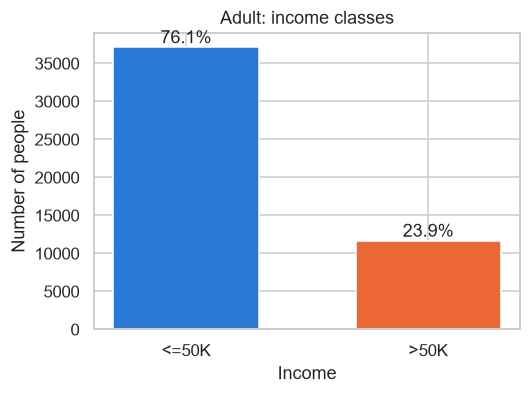

In [8]:
counts = df[TARGET].value_counts()
shares = df[TARGET].value_counts(normalize=True)
print(pd.DataFrame({"count": counts, "share": shares.round(3)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=[BLUE, ORANGE], width=0.6)
for bar, share in zip(bars, shares.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{share:.1%}",
            ha="center", va="bottom")
ax.set_title("Adult: income classes")
ax.set_xlabel("Income")
ax.set_ylabel("Number of people")
fig.savefig(FIG_DIR / "adult_class_balance.png")
plt.show()

## 6. Numeric columns

Summary statistics & histograms. The skewness column helps spot long tails (roughly: |skew| > 1 is strongly skewed). The last column is the share of exact zeros.

In [9]:
stats = df[num_cols].describe().T
stats["skew"] = df[num_cols].skew()
stats["share_zero"] = (df[num_cols] == 0).mean()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,share_zero
age,48842.0,38.64,13.71,17.0,28.0,37.0,48.0,90.0,0.56,0.00
fnlwgt,48842.0,189664.13,105604.03,12285.0,117550.5,178144.5,237642.0,1490400.0,1.44,0.00
education-num,48842.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0,-0.32,0.00
capital-gain,48842.0,1079.07,7452.02,0.0,0.0,0.0,0.0,99999.0,11.89,0.92
capital-loss,48842.0,87.50,403.00,0.0,0.0,0.0,0.0,4356.0,4.57,0.95
hours-per-week,48842.0,40.42,12.39,1.0,40.0,40.0,45.0,99.0,0.24,0.00


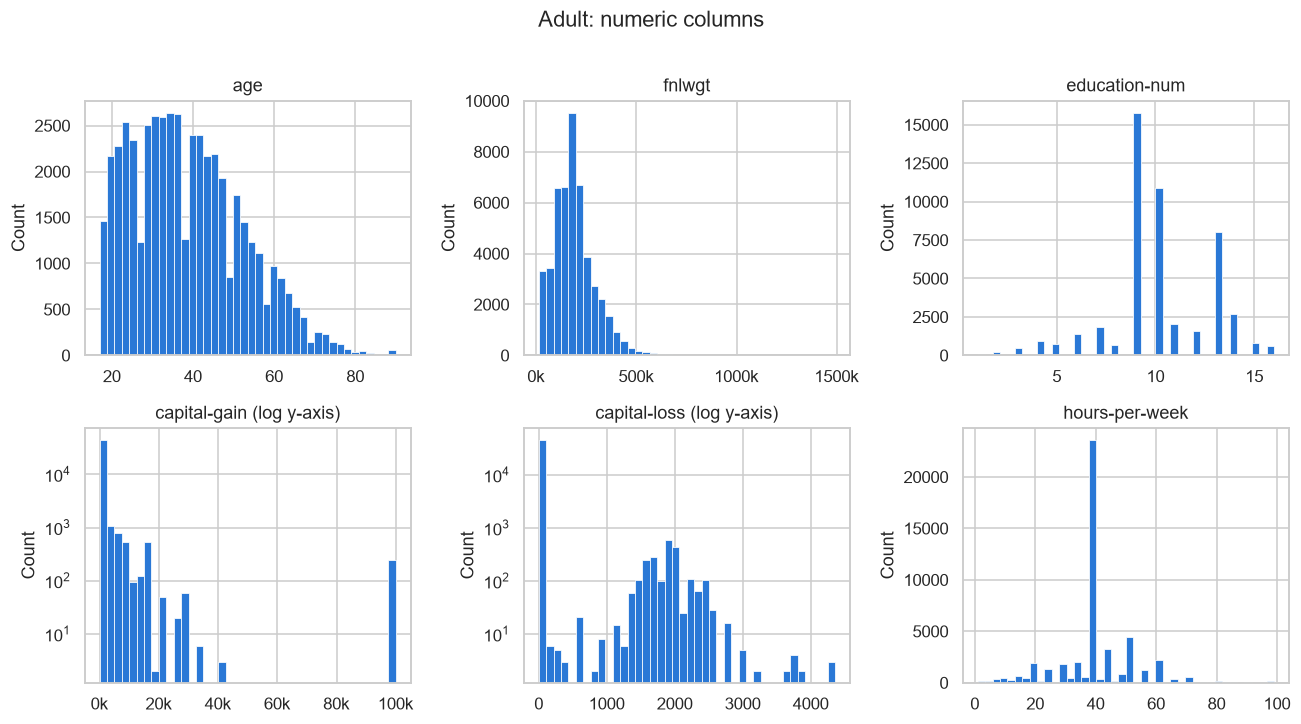

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(df[col], bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(col)
    ax.set_ylabel("Count")
    # capital-gain/loss are almost all zero, a log y-axis shows the tail
    if col in ("capital-gain", "capital-loss"):
        ax.set_yscale("log")
        ax.set_title(col + " (log y-axis)")
    # write large numbers as 50k, 100k, ... so the tick labels don't overlap
    if col in ("fnlwgt", "capital-gain"):
        ax.xaxis.set_major_formatter(lambda value, _: f"{value / 1000:.0f}k")
fig.suptitle("Adult: numeric columns", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "adult_numeric_distributions.png")
plt.show()

In [11]:
# capital-gain has an outlier: 99999
print("Rows with capital-gain == 99999:", (df["capital-gain"] == 99999).sum())
print("Most common hours-per-week:", df["hours-per-week"].value_counts().head(3).to_dict())

Rows with capital-gain == 99999: 244
Most common hours-per-week: {40: 22803, 50: 4246, 45: 2717}


What stands out:
- `capital-gain` and `capital-loss` are over 90% zeros with a long tail. A model that assumes a smooth
  distribution (like a Gaussian) will spread values around zero instead of keeping the spike.
  CTGAN's mode-specific normalisation was designed for exactly this kind of column.
- `capital-gain` has a block of rows at 99999, which looks like a top-code.
- `hours-per-week` has a big spike at 40 (full-time work).
- `fnlwgt` is a census sampling weight, not a personal attribute. Many papers keep it, so we keep it for
  comparability, but it is very skewed.

## 7. Categorical columns

How many levels does each column have, and how many of those levels are rare? Here a level is
called rare if less than 1% of rows have it.

In [12]:
rows = []
for col in cat_cols:
    shares = df[col].value_counts(normalize=True)
    rows.append({
        "column": col,
        "levels": df[col].nunique(),
        "rare_levels (<1%)": int((shares < 0.01).sum()),
        "most_common": shares.index[0],
        "most_common_share": round(shares.iloc[0], 3),
    })
cat_summary = pd.DataFrame(rows).set_index("column")
cat_summary

,levels,rare_levels (<1%),most_common,most_common_share
column,,,,
workclass,8,2,Private,0.736
education,16,2,HS-grad,0.323
marital-status,7,1,Married-civ-spouse,0.458
occupation,14,2,Prof-specialty,0.134
relationship,6,0,Husband,0.404
race,5,2,White,0.855
sex,2,0,Male,0.668
native-country,41,39,United-States,0.913


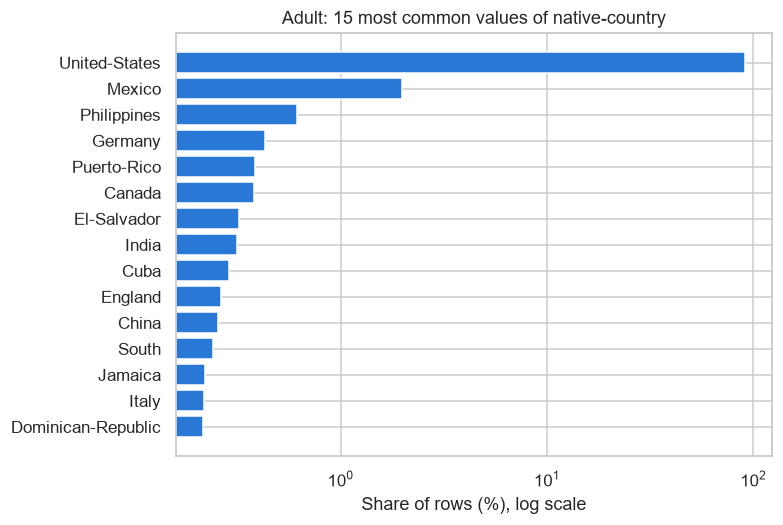

In [13]:
# native-country is the extreme case: one level dominates and most others are tiny
country_share = df["native-country"].value_counts(normalize=True).head(15).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(country_share.index, country_share.values * 100, color=BLUE)
ax.set_xscale("log")
ax.set_xlabel("Share of rows (%), log scale")
ax.set_title("Adult: 15 most common values of native-country")
fig.savefig(FIG_DIR / "adult_native_country.png")
plt.show()

`native-country` has about 40 levels, but one of them (`United-States`) covers about 90% of rows and
most of the others are well under 1%. This is the kind of column where we expect generators to lose
rare categories, and it is worth checking per-category frequencies in the synthetic data later.

## 8. Relationships between columns

Our research questions include whether generators keep the *dependencies* between columns, not just the
single-column distributions. So we need to know which dependencies are there in the real data.

- numeric vs numeric: Spearman correlation (rank-based, so it is less affected by the long tails)
- categorical vs categorical (including the target): Cramér's V, which goes from 0 (no association) to 1

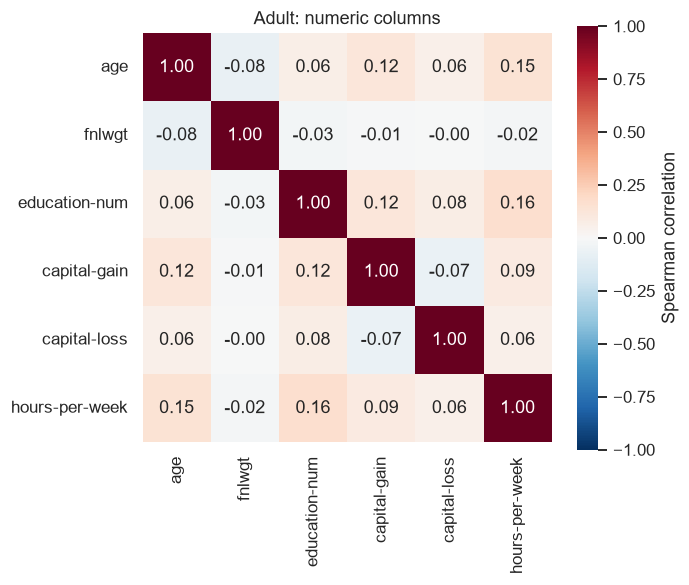

In [14]:
spearman = df[num_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Adult: numeric columns")
fig.savefig(FIG_DIR / "adult_spearman.png")
plt.show()

In [15]:
from scipy.stats import chi2_contingency


def cramers_v(x, y):
    """Cramér's V between two categorical columns (0 = no association, 1 = perfect)."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

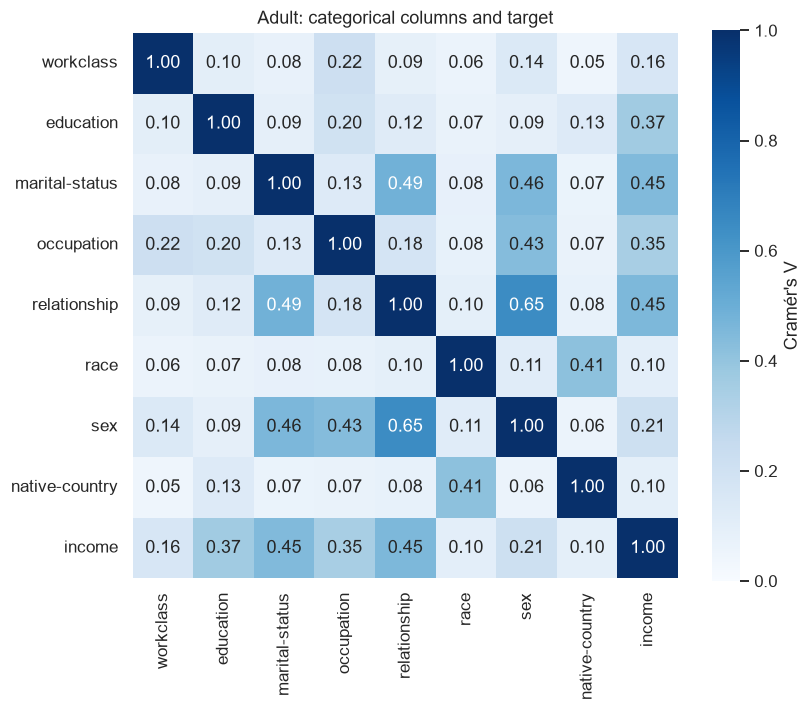

In [16]:
cat_and_target = cat_cols + [TARGET]
cramers = pd.DataFrame(index=cat_and_target, columns=cat_and_target, dtype=float)
for a in cat_and_target:
    for b in cat_and_target:
        if a == b:
            cramers.loc[a, b] = 1.0
            continue
        # rows with a missing value in either column are left out for that pair
        pair = df[[a, b]].dropna()
        cramers.loc[a, b] = cramers_v(pair[a], pair[b])

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cramers, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Cramér's V"})
ax.set_title("Adult: categorical columns and target")
fig.savefig(FIG_DIR / "adult_cramers_v.png")
plt.show()

The strongest associations are between `relationship`, `marital-status` and `sex` (for example, `Husband` implies `Married-civ-spouse` and `Male`). These are near-deterministic rules, so
they make a good test: a synthetic row with `relationship = Husband` and `sex = Female` is a sign that the generator did not learn the dependency. `relationship` and `marital-status` are also the columns most
associated with income.

## 9. Duplicate rows

Duplicates matter for the privacy part of the project.

In [17]:
n_dup = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dup} ({n_dup / len(df):.2%})")

Exact duplicate rows: 52 (0.11%)


## 10. Summary for the report

One row for the dataset table in the M1 report 
`Cols` counts all columns including the target; `Numeric` and `Categorical` count the features only.

In [18]:
summary = pd.DataFrame([{
    "dataset": "Adult (UCI)",
    "rows": len(df),
    "cols": df.shape[1],
    "numeric": len(num_cols),
    "categorical": len(cat_cols),
    "target": "income (>50K)",
    "minority_share": round(df[TARGET].value_counts(normalize=True).min(), 3),
    "rows_with_missing": int(df.isna().any(axis=1).sum()),
    "missing_note": "'?' in workclass, occupation, native-country",
}])
summary.to_csv(RES_DIR / "adult_summary.csv", index=False)

s = summary.iloc[0]
print(f"Adult (UCI) & {s.rows:,} & {s.cols} & {s.numeric} & {s.categorical} & income ($>$50K) & "
      f"{s.rows_with_missing:,} rows ({s.rows_with_missing / s.rows:.1%}) \\\\")
summary

Adult (UCI) & 48,842 & 15 & 6 & 8 & income ($>$50K) & 3,620 rows (7.4%) \\


,dataset,rows,cols,numeric,categorical,target,minority_share,rows_with_missing,missing_note
0,Adult (UCI),48842,15,6,8,income (>50K),0.239,3620,"'?' in workclass, occupation, native-country"
